# Домашня робота №7

# Перетворення випадкових величин

In [74]:
import numpy as np
import matplotlib.pyplot as plt

## 1 Квантильне перетворення

### 1.1 Задана щільність

Нехай випадкова величина $\xi$ має щільність
$f(x) = a \sin(x) I_{[0, \pi]}(x),$
де $I_{[c, d]}(x)$ - індикатор на відрізку $[c, d]$.

Знайдіть значення параметра $a$.

Згенеруйте $n = 100000$ значень випадкової величини $\xi$ за допомогою квантильного перетворення.

Намалюйте нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\xi$ разом з її функцією щільності.

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from math import acos

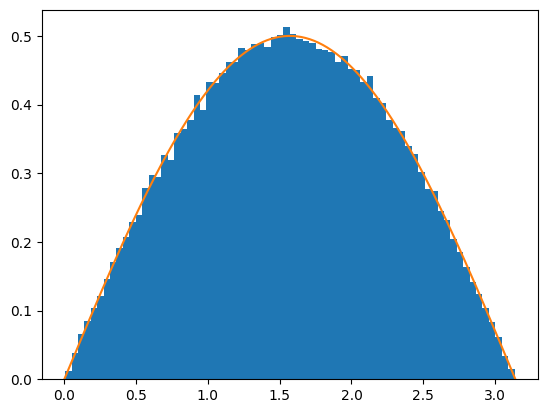

In [76]:
from scipy.stats import uniform
n = 100000
xi = uniform.rvs(size=n)
nu = np.acos(-2*xi+1)

_ = plt.hist(nu, density=True, bins="auto")
x = np.arange(0, np.pi, 0.01)
y = 0.5 * np.sin(x)
plt.plot(x, y)


### 1.2 Нормальний розподіл

Нехай випадкова величина $\xi \sim N(0, 1)$.

Згенеруйте $n = 100000$ значень випадкової величини $\xi$ за допомогою квантильного перетворення.

Намалюйте нормовану гістограму отриманих $n = 100000$ значень випадкової величини $\xi$ разом з її функцією щільності.

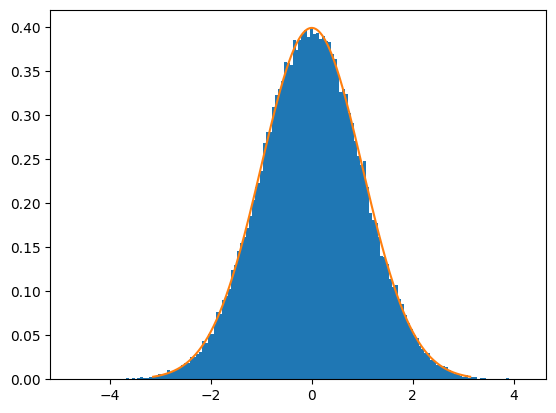

In [77]:
from scipy.stats import norm
n = 100000
xi = uniform.rvs(size=n)
ksi = norm(0, 1)

def inv(x):
    return norm.ppf(x)
    
nu = np.array([inv(x) for x in xi])

_ = plt.hist(nu, density=True, bins="auto")
x = np.arange(-np.pi, np.pi, 0.01)
y = ksi.pdf(x)
plt.plot(x, y)

## 2 Відсутність пам'яті

Розглянемо випадкову величину $\xi$ з геометричного розподілу з параметром $p = 0.5$.
Тобто $\xi \sim Geom(0.5)$.

1. Згенеруйте $n = 10000$ значень випадкової величини $\xi$;
2. Реалізуйте 2 сабплоти в одному рядку;
3. На першому сабплоті намалюйте:
   - нормовану гістограму згенерованих $n = 10000$ значень випадкової величини $\xi$;
   - функцію ймовірностей випадкової величини $\xi$;
4. Отримайте $n = 10000$ значень випадкової величини $\eta = (\xi - 1) I_{(\xi - 1) > 0}$;
5. На другому сабплоті намалюйте:
   - нормовану гістограму отриманих значень випадкової величини $\eta$;
   - функцію ймовірностей випадкової величини $\xi$.

**Зауваження 1.** Графік функції ймовірнстей краще малювати для $10$ значень.

**Зауваження 2.** У гістограмах проміжок значень слід розбивати на одиничні інтервали.

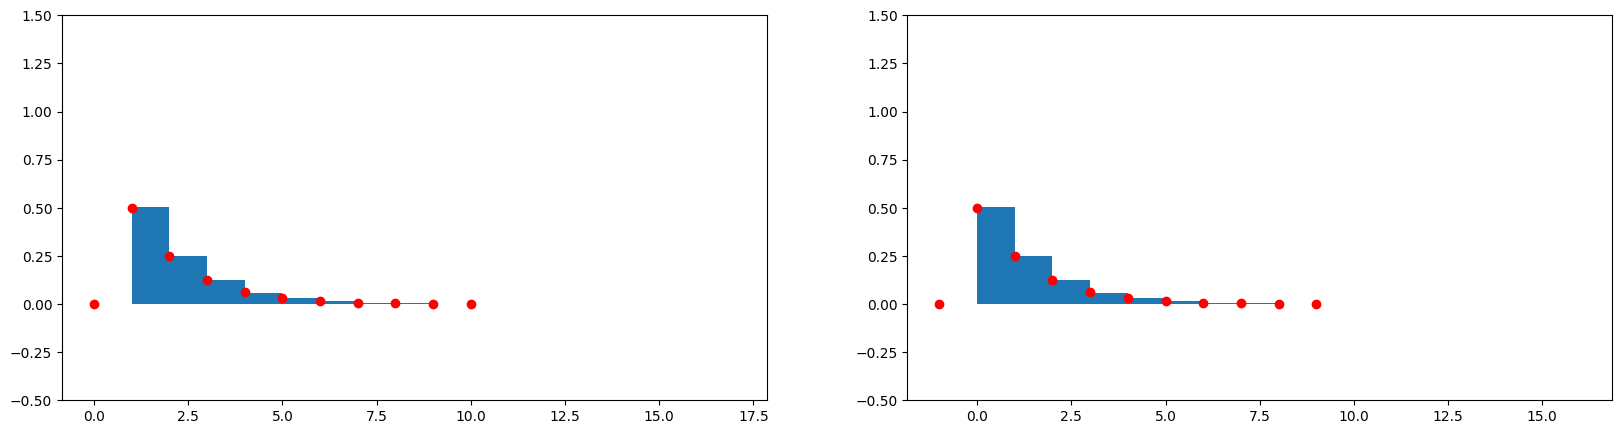

In [78]:
from scipy.stats import geom
x = np.arange(0, 11)

xi = geom(0.5)
xi_rvs = xi.rvs(size=10000)
pmf = geom.pmf(x, 0.5)

fig = plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1, ylim=(-0.5, 1.5))
plt.hist(xi_rvs, density=True, bins="auto")
plt.scatter(x, pmf, c='red')

ksi_rvs = np.array(xi_rvs) - 1

plt.subplot(1, 2, 2, ylim=(-0.5, 1.5))
plt.hist(ksi_rvs, density=True, bins="auto")
plt.scatter(x-1, pmf, c='red')

plt.show()

## 3 Задача 1.11.3

Розглянемо випадкову величину $\xi$ зі стандартного експоненційного розподілу.
Тобто $\xi \sim Exp(1)$.

### 3.1 Експонента

1. Згенеруйте $n = 10000$ значень випадкової величини $\xi$;
2. Реалізуйте 2 сабплоти в одному рядку;
3. На першому сабплоті намалюйте:
   - нормовану гістограму згенерованих $n = 10000$ значень випадкової величини $\xi$;
   - функцію щільності випадкової величини $\xi$;
4. Отримайте $n = 10000$ значень випадкової величини $\eta = \exp\{-\xi\}$ (застосуйте функцію модуль до згенерованих $n = 10000$ значень випадкової величини $\xi$);
5. На другому сабплоті намалюйте:
   - нормовану гістограму отриманих $n = 10000$ значень випадкової величини $\eta$;
   - функцію щільності випадкової величини $\xi$;
   - функцію щільності випадкової величини $\eta$.

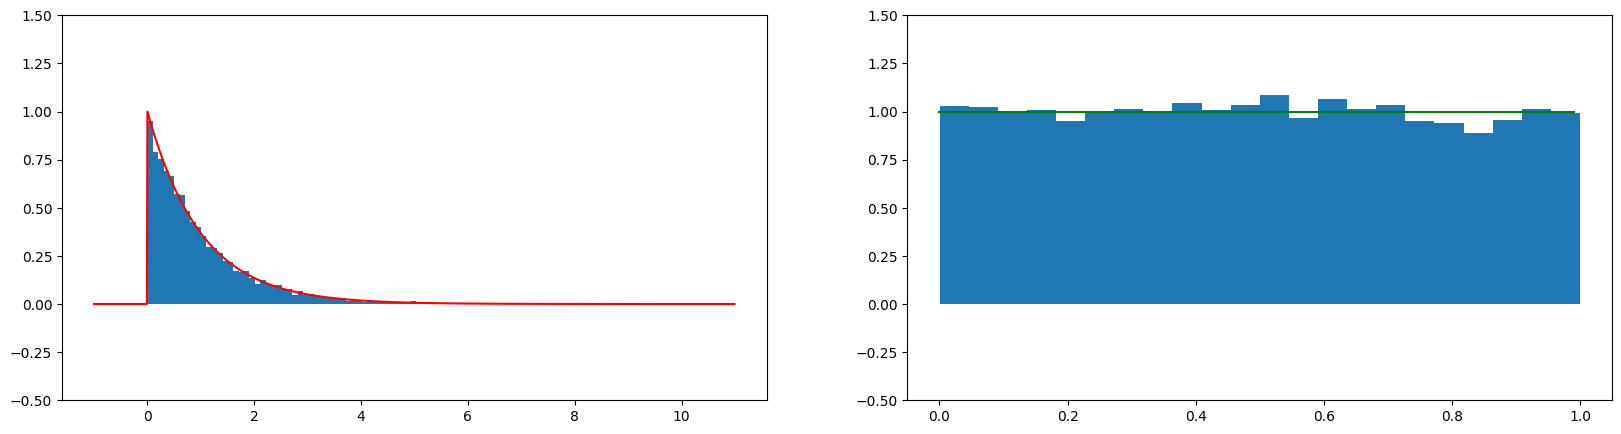

In [79]:
from scipy.stats import expon
x = np.arange(-1, 11, 0.01)

xi = expon(0, 1)
xi_rvs = xi.rvs(size=10000)
pdf = expon.pdf(x, 0, 1)

fig = plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1, ylim=(-0.5, 1.5))
plt.hist(xi_rvs, density=True, bins="auto")
plt.plot(x, pdf, c='red')

ksi_rvs = np.exp(-np.array(xi_rvs))

plt.subplot(1, 2, 2, ylim=(-0.5, 1.5))
plt.hist(ksi_rvs, density=True, bins="auto")
plt.plot(np.arange(0, 1, 0.01), uniform.pdf(np.arange(0, 1, 0.01), 0, 1), c='g')

plt.show()

### 3.2 Квадрат

1. Згенеруйте $n = 10000$ значень випадкової величини $\xi$;
2. Реалізуйте 2 сабплоти в одному рядку;
3. На першому сабплоті намалюйте:
   - нормовану гістограму згенерованих $n = 10000$ значень випадкової величини $\xi$;
   - функцію щільності випадкової величини $\xi$;
4. Отримайте $n = 10000$ значень випадкової величини $\eta = \xi^2$ (застосуйте функцію модуль до згенерованих $n = 10000$ значень випадкової величини $\xi$);
5. На другому сабплоті намалюйте:
   - нормовану гістограму отриманих $n = 10000$ значень випадкової величини $\eta$;
   - функцію щільності випадкової величини $\xi$;
   - функцію щільності випадкової величини $\eta$.

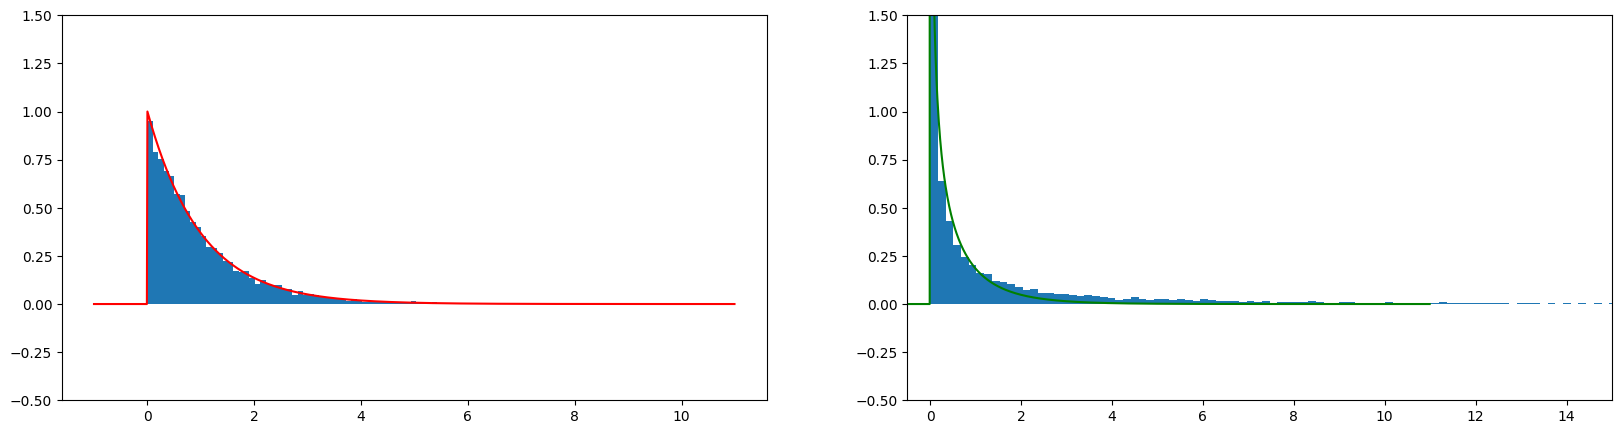

In [80]:
fig = plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1, ylim=(-0.5, 1.5))
plt.hist(xi_rvs, density=True, bins="auto")
plt.plot(x, pdf, c='red')

eta_rvs = np.array(xi_rvs) ** 2

plt.subplot(1, 2, 2, xlim=(-0.5, 15), ylim=(-0.5, 1.5))
plt.hist(eta_rvs, density=True, bins="auto")

def density(x):
    if x > 0:
        return np.exp(-x)/(2*np.sqrt(x))
    else:
        return 0
pdf_eta = [density(i) for i in x]
plt.plot(x, pdf_eta, c='g')

plt.show()

## 4 Задача 1.11.5

Розглянемо випадкову величину $\xi$ зі стандартного рівномірного розподілу.
Тобто $\xi \sim Unif(0, 1)$.

### 4.1 Лінійне перетворення

1. Згенеруйте $n = 10000$ значень випадкової величини $\xi$;
2. Реалізуйте 2 сабплоти в одному рядку;
3. На першому сабплоті намалюйте:
   - нормовану гістограму згенерованих $n = 10000$ значень випадкової величини $\xi$;
   - функцію щільності випадкової величини $\xi$;
4. Отримайте $n = 10000$ значень випадкової величини $\eta = 3 \xi - 2$ (застосуйте функцію модуль до згенерованих $n = 10000$ значень випадкової величини $\xi$);
5. На другому сабплоті намалюйте:
   - нормовану гістограму отриманих $n = 10000$ значень випадкової величини $\eta$;
   - функцію щільності випадкової величини $\xi$;
   - функцію щільності випадкової величини $\eta$.

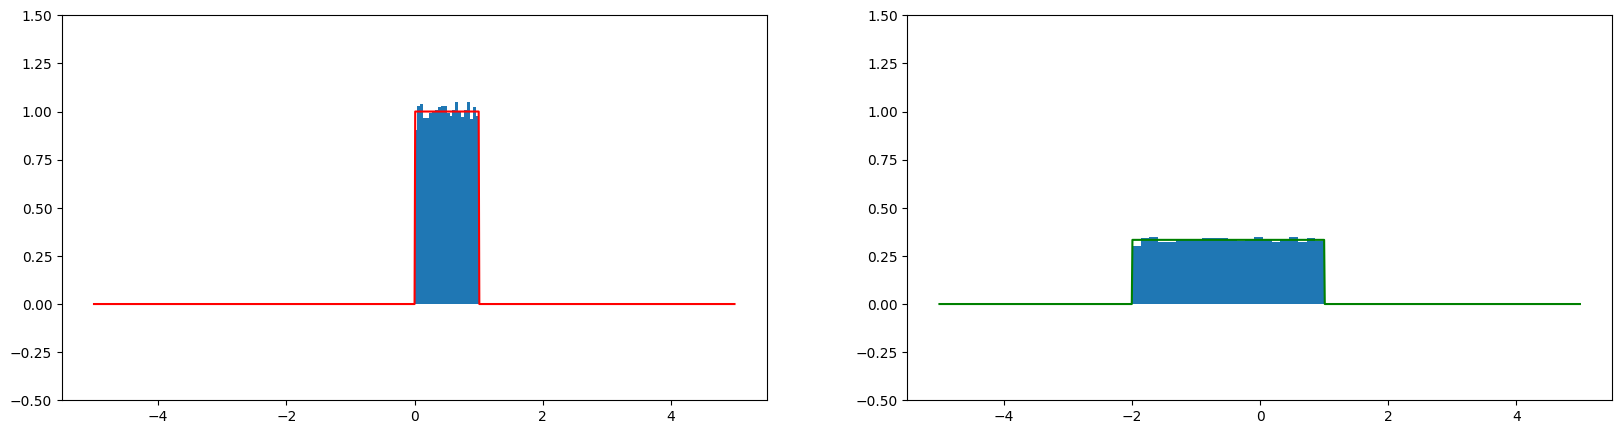

In [82]:
xi_rvs = uniform.rvs(size=10000)
x = np.arange(-5, 5, 0.01)
pdf = uniform.pdf(x)

fig = plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1, ylim=(-0.5, 1.5))
plt.hist(xi_rvs, density=True, bins="auto")
plt.plot(x, pdf, c='red')

eta_rvs = 3*xi_rvs - 2
plt.subplot(1, 2, 2, ylim=(-0.5, 1.5))
plt.hist(eta_rvs, density=True, bins="auto")

def density(x):
    if -2 <= x <= 1:
        return 1/3
    else:
        return 0
pdf_eta = [density(i) for i in x]
plt.plot(x, pdf_eta, c='g')

plt.show()

### 4.2 Модуль від лінійного перетворення

1. Згенеруйте $n = 10000$ значень випадкової величини $\xi$;
2. Реалізуйте 2 сабплоти в одному рядку;
3. На першому сабплоті намалюйте:
   - нормовану гістограму згенерованих $n = 10000$ значень випадкової величини $\xi$;
   - функцію щільності випадкової величини $\xi$;
4. Отримайте $n = 10000$ значень випадкової величини $\eta = |2 \xi - 1|$ (застосуйте функцію модуль до згенерованих $n = 10000$ значень випадкової величини $\xi$);
5. На другому сабплоті намалюйте:
   - нормовану гістограму отриманих $n = 10000$ значень випадкової величини $\eta$;
   - функцію щільності випадкової величини $\xi$;
   - функцію щільності випадкової величини $\eta$.

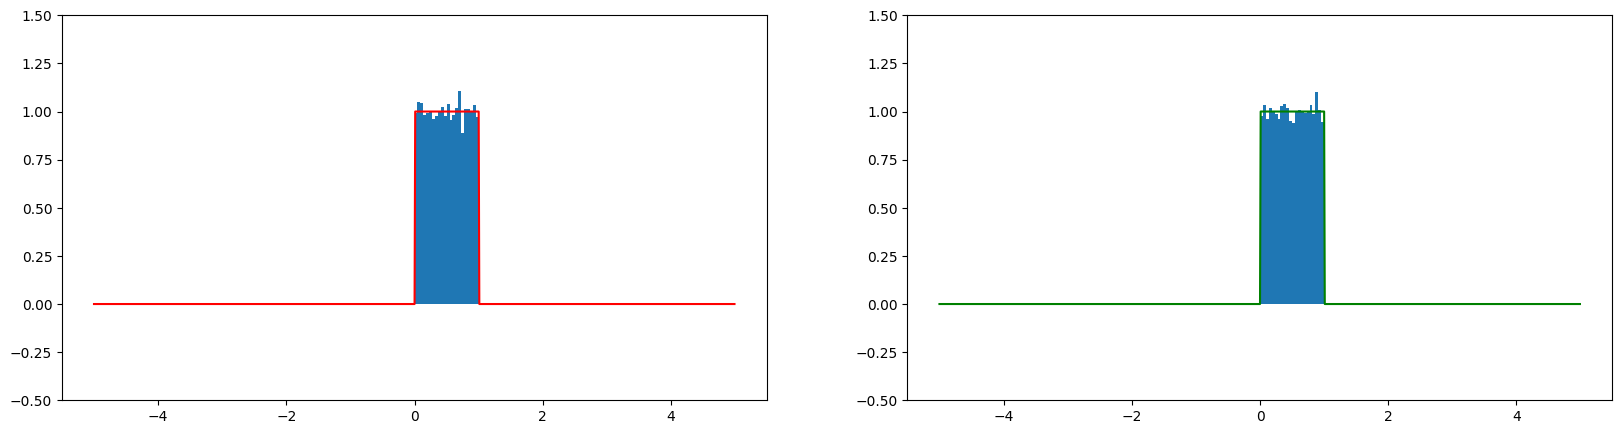

In [83]:
xi_rvs = uniform.rvs(size=10000)
x = np.arange(-5, 5, 0.01)
pdf = uniform.pdf(x)

fig = plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1, ylim=(-0.5, 1.5))
plt.hist(xi_rvs, density=True, bins="auto")
plt.plot(x, pdf, c='red')

eta_rvs = np.abs(2*xi_rvs-1)
plt.subplot(1, 2, 2, ylim=(-0.5, 1.5))
plt.hist(eta_rvs, density=True, bins="auto")

def density(x):
    if 0 <= x <= 1:
        return 1
    else:
        return 0
pdf_eta = [density(i) for i in x]
plt.plot(x, pdf_eta, c='g')

plt.show()

### 4.3 Логарифм

1. Згенеруйте $n = 10000$ значень випадкової величини $\xi$;
2. Реалізуйте 2 сабплоти в одному рядку;
3. На першому сабплоті намалюйте:
   - нормовану гістограму згенерованих $n = 10000$ значень випадкової величини $\xi$;
   - функцію щільності випадкової величини $\xi$;
4. Отримайте $n = 10000$ значень випадкової величини $\eta = - \log \xi$ (застосуйте функцію модуль до згенерованих $n = 10000$ значень випадкової величини $\xi$);
5. На другому сабплоті намалюйте:
   - нормовану гістограму отриманих $n = 10000$ значень випадкової величини $\eta$;
   - функцію щільності випадкової величини $\xi$;
   - функцію щільності випадкової величини $\eta$.

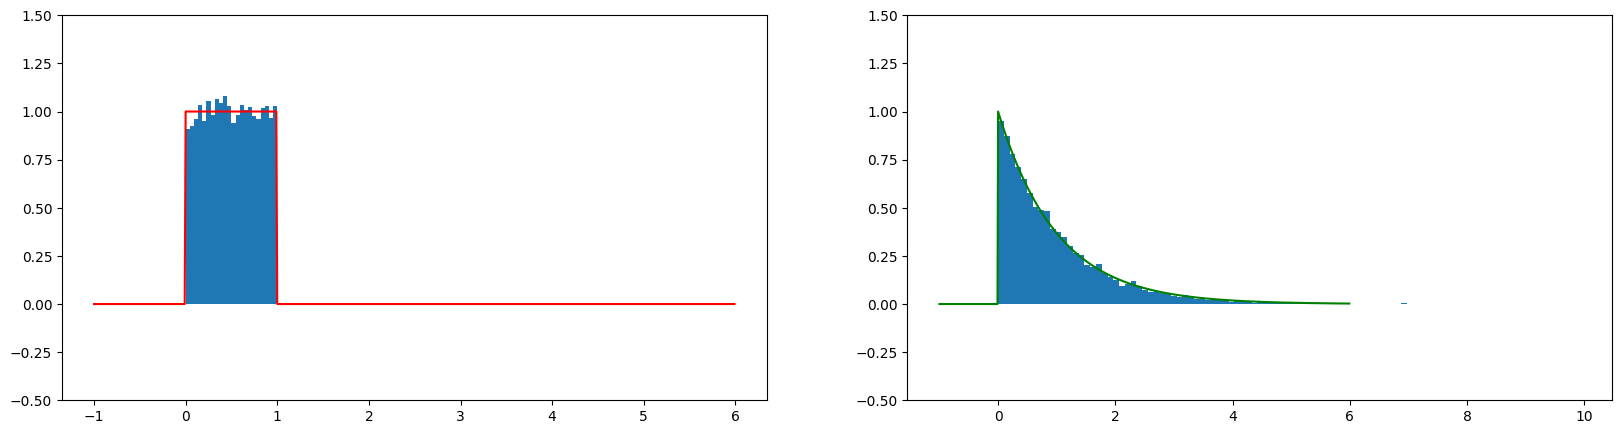

In [84]:
xi_rvs = uniform.rvs(size=10000)
x = np.arange(-1, 6, 0.01)
pdf = uniform.pdf(x)

fig = plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1, ylim=(-0.5, 1.5))
plt.hist(xi_rvs, density=True, bins="auto")
plt.plot(x, pdf, c='red')

eta_rvs = -np.log(xi_rvs)
plt.subplot(1, 2, 2, ylim=(-0.5, 1.5))
plt.hist(eta_rvs, density=True, bins="auto")

def density(x):
    if x > 0:
        return np.exp(-x)
    else:
        return 0
pdf_eta = [density(i) for i in x]
plt.plot(x, pdf_eta, c='g')

plt.show()

## 5 Одиничний квадрат

Реалізуйте вадкову величину рівномірно розподілену на одиничному квадраті.
Тобто $\xi = (x, y), \quad x, y \sim Unif(0, 1)$.

In [86]:
eta1 = uniform(loc=0, scale=1)
eta2 = uniform(loc=0, scale=1)

Знайдіть функцію щільності випадкової величини $\xi_1 = x^2 + y^2$.
Намалюйте її разом із нормованою гістограмою $n = 100000$ значень випадкової величини $\xi_1$,
отриманою перетвореннями випадкових величин $x, y$.

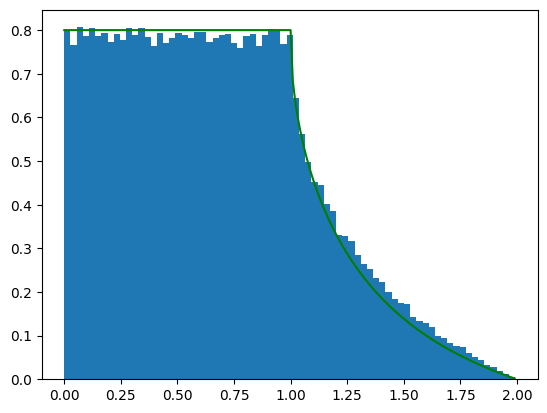

In [87]:
x = np.arange(0, 1, 0.01)
y = np.arange(0, 1, 0.01)

eta1_rvs = np.array(uniform.rvs(size=100_000))
eta2_rvs = np.array(uniform.rvs(size=100_000))

ksi1_rvs = eta1_rvs ** 2 + eta2_rvs ** 2

plt.hist(ksi1_rvs, density=True, bins="auto")

def density(x):
    if 0 <= x <= 1:
        return 0.8
    elif 1 <= x <= 2:
        return (np.asin(1/np.sqrt(x))-np.asin(np.sqrt(x-1)/np.sqrt(x)))/(2*np.sqrt(x))
    else:
        return 0

x_vals = np.arange(0, 2, 0.01)
pdf_eta = [density(i) for i in x_vals]
plt.plot(x_vals, pdf_eta, c='g')
plt.show()

Знайдіть функцію щільності випадкової величини $\xi_2 = \max (x, y)$.
Намалюйте її разом із нормованою гістограмою $n = 100000$ значень випадкової величини $\xi_2$,
отриманою перетвореннями випадкових величин $x, y$.

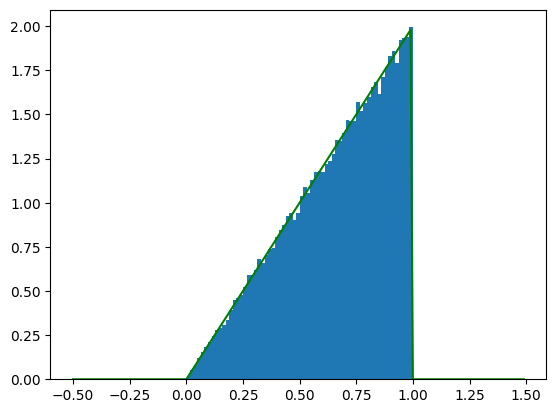

In [88]:
ksi2_rvs = np.array([eta1_rvs[i] if eta1_rvs[i] >= eta2_rvs[i] else eta2_rvs[i] for i in range(len(eta1_rvs))])

plt.hist(ksi2_rvs, density=True, bins="auto")

def density(x):
    if 0 <= x <= 1:
        return 2*x
    else:
        return 0

x_vals = np.arange(-0.5, 1.5, 0.01)
pdf_eta = [density(i) for i in x_vals]
plt.plot(x_vals, pdf_eta, c='g')
plt.show()

Знайдіть функцію щільності випадкової величини $\xi_3 = |x - y|$.
Намалюйте її разом із нормованою гістограмою $n = 100000$ значень випадкової величини $\xi_3$,
отриманою перетвореннями випадкових величин $x, y$.

In [89]:
a = np.array([1, 2, 3])
b = np.array([1, 2, 4])
a-b

array([ 0,  0, -1])

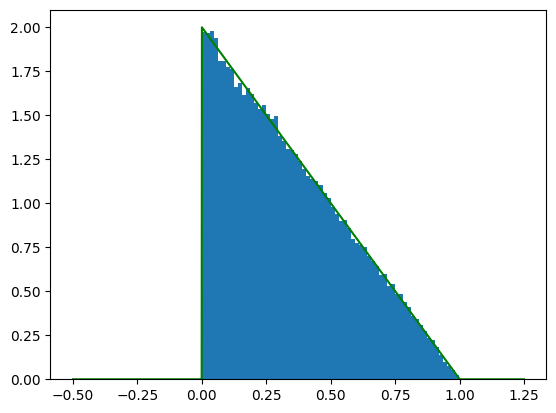

In [90]:
ksi3_rvs = np.abs(eta1_rvs - eta2_rvs)

plt.hist(ksi3_rvs, density=True, bins="auto")

def density(x):
    if 0 < x <= 1:
        return 2 - 2*x
    else:
        return 0

x_vals = np.arange(-0.5, 1.25, 0.001)
pdf_eta = [density(i) for i in x_vals]
plt.plot(x_vals, pdf_eta, c='g')
plt.show()